# Projeto Final – Analista de Dados (EBAC)
## Acidentes nas rodovias federais de Pernambuco (PRF, 2025)
### Etapa 2 – Análise Exploratória dos Dados (EDA)

Objetivo: entender as características dos dados **antes do tratamento**, identificando padrões, tendências,
anomalias e relações entre variáveis. Os problemas de qualidade encontrados aqui viram a lista de tarefas da Etapa 3.

**Análises realizadas**
1. Qualidade dos dados (nulos, "Ignorado", valores impossíveis, duplicatas)
2. Tendência temporal (mês, dia da semana × hora)
3. Distribuição, média e mediana (idade das vítimas e variáveis do acidente)
4. Outliers (boxplot + regra do IQR)
5. Correlação entre variáveis numéricas
6. Categorias: causas, tipos e letalidade
7. Dispersão: mapa dos acidentes e acidentes × população por município (cruzamento com IBGE)
8. Perfil das vítimas (cruzamento ocorrências × pessoas)
9. Onde os acidentes se concentram (BR e trechos de km)

**Entrada:** envie para o Colab os 3 arquivos gerados na Etapa 1: `pe_ocorrencias.csv`, `pe_pessoas.csv`, `pe_populacao.csv`.

In [1]:
import re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option('display.max_columns', 50)

# Paleta e estilo (cores fixas por função: azul = volume, vermelho = mortes/gravidade)
AZUL, AZUL_CLARO, VERMELHO, CINZA = '#2a78d6', '#9ec5f4', '#d03b3b', '#52514e'
plt.rcParams.update({
    'figure.figsize': (10, 4.5), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#b5b4ae', 'axes.labelcolor': CINZA, 'xtick.color': CINZA, 'ytick.color': CINZA,
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})

### 0. Carregar dados e preparar o mínimo para explorar

In [2]:
oc  = pd.read_csv('pe_ocorrencias.csv', low_memory=False)
pes = pd.read_csv('pe_pessoas.csv', low_memory=False)
pop = pd.read_csv('pe_populacao.csv')

# Conversões só para conseguir explorar (o tratamento completo é na Etapa 3)
oc['data']    = pd.to_datetime(oc['data_inversa'], errors='coerce', dayfirst=False)
oc['hora']    = pd.to_datetime(oc['horario'], format='%H:%M:%S', errors='coerce').dt.hour
oc['mes']     = oc['data'].dt.month
oc['com_morte'] = oc['mortos'] > 0

def chave(s):
    # Padroniza nome de município: sem acento, maiúsculo
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode()
    return re.sub(r'\s+', ' ', re.sub(r'[^A-Za-z ]', ' ', s)).strip().upper()

print(f'Ocorrências: {len(oc):,} | Pessoas: {len(pes):,} | Municípios (IBGE): {len(pop):,}')
print('Período:', oc['data'].min().date(), 'a', oc['data'].max().date())

Ocorrências: 3,013 | Pessoas: 7,646 | Municípios (IBGE): 185
Período: 2025-01-01 a 2025-12-31


### 1. Qualidade dos dados
Verificamos valores ausentes, categorias "Ignorado/Não informado", valores impossíveis e linhas duplicadas.

In [3]:
def nulos(df, nome):
    n = df.isna().sum()
    n = n[n > 0].sort_values(ascending=False)
    return pd.DataFrame({'tabela': nome, 'coluna': n.index, 'nulos': n.values,
                         '% nulos': (n.values / len(df) * 100).round(1)})

display(pd.concat([nulos(oc, 'ocorrencias'), nulos(pes, 'pessoas')], ignore_index=True))

,tabela,coluna,nulos,% nulos
0,ocorrencias,uop,1,0.0
1,pessoas,tipo_envolvido,347,4.5
2,pessoas,sexo,347,4.5
3,pessoas,estado_fisico,347,4.5
4,pessoas,tipo_veiculo,305,4.0
5,pessoas,uop,4,0.1


In [4]:
# Categorias que significam "sem informação"
SEM_INFO = r'(?i)^(ignorad[oa]|n[aã]o informado|nao informado|\(null\)|null)$'

def contar_sem_info(df, nome):
    linhas = []
    for c in [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]:
        qtd = df[c].astype(str).str.strip().str.match(SEM_INFO).sum()
        if qtd:
            linhas.append({'tabela': nome, 'coluna': c, 'qtd': qtd, '%': round(qtd / len(df) * 100, 1)})
    return pd.DataFrame(linhas)

display(pd.concat([contar_sem_info(oc, 'ocorrencias'), contar_sem_info(pes, 'pessoas')], ignore_index=True))

,tabela,coluna,qtd,%
0,ocorrencias,sentido_via,9,0.3
1,ocorrencias,condicao_metereologica,32,1.1
2,pessoas,sentido_via,20,0.3
3,pessoas,condicao_metereologica,72,0.9
4,pessoas,estado_fisico,677,8.9
5,pessoas,sexo,686,9.0


In [5]:
problemas = {
    'Ocorrências duplicadas (id)': oc['id'].duplicated().sum(),
    'Pessoas duplicadas (pesid)': pes['pesid'].duplicated().sum() if 'pesid' in pes else 'n/a',
    'Idade < 0 ou > 100': ((pes['idade'] < 0) | (pes['idade'] > 100)).sum(),
    'Idade ausente': pes['idade'].isna().sum(),
    'Ano do veículo > 2026 ou < 1950': ((pes['ano_fabricacao_veiculo'] > 2026) | (pes['ano_fabricacao_veiculo'] < 1950)).sum()
                                        if 'ano_fabricacao_veiculo' in pes else 'n/a',
    'Data inválida': oc['data'].isna().sum(),
    'Lat/long fora de PE': (~oc['latitude'].between(-10, -7) | ~oc['longitude'].between(-42, -32)).sum(),
    'Município fora do IBGE': (~oc['municipio'].map(chave).isin(pop['municipio'].map(chave))).sum(),
}
pd.Series(problemas, name='quantidade').to_frame()

,quantidade
Ocorrências duplicadas (id),0
Pessoas duplicadas (pesid),346
Idade < 0 ou > 100,4
Idade ausente,0
Ano do veículo > 2026 ou < 1950,923
Data inválida,0
Lat/long fora de PE,0
Município fora do IBGE,20


> **Leitura:** anote aqui os principais problemas (eles serão tratados na Etapa 3).
> Ex.: idades impossíveis, "Ignorado" em sexo/estado físico, coordenadas fora de PE, município com grafia diferente do IBGE.

### 2. Tendência temporal

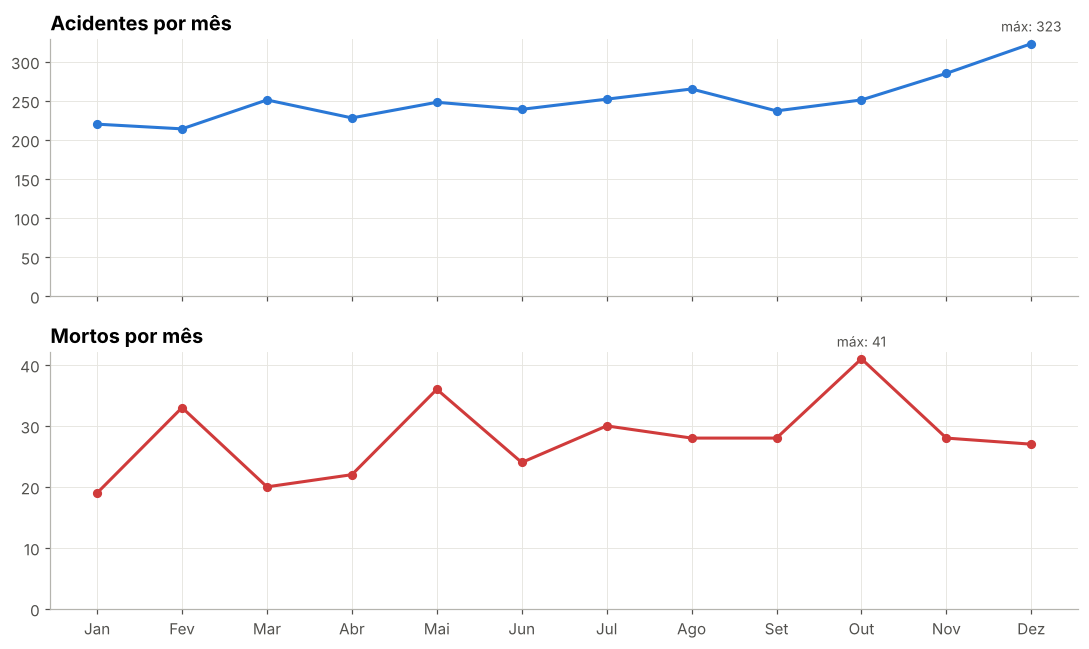

,Jan,Fev,Mar,Abr,Mai,Jun,Jul,Ago,Set,Out,Nov,Dez
acidentes,220,214,251,228,248,239,252,265,237,251,285,323
mortos,19,33,20,22,36,24,30,28,28,41,28,27


In [6]:
por_mes = oc.groupby('mes').agg(acidentes=('id', 'count'), mortos=('mortos', 'sum'))
nomes_mes = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']
por_mes.index = [nomes_mes[m - 1] for m in por_mes.index]

# Duas medidas com escalas diferentes -> dois gráficos (nunca eixo duplo)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
a1.plot(por_mes.index, por_mes['acidentes'], color=AZUL, lw=2, marker='o', ms=5)
a1.set_title('Acidentes por mês')
a2.plot(por_mes.index, por_mes['mortos'], color=VERMELHO, lw=2, marker='o', ms=5)
a2.set_title('Mortos por mês')
for a, col in [(a1, 'acidentes'), (a2, 'mortos')]:
    i = por_mes[col].idxmax()
    a.annotate(f'máx: {por_mes[col].max()}', (i, por_mes[col].max()), textcoords='offset points',
               xytext=(0, 8), ha='center', color=CINZA, fontsize=9)
    a.set_ylim(bottom=0)
plt.tight_layout(); plt.show()
por_mes.T

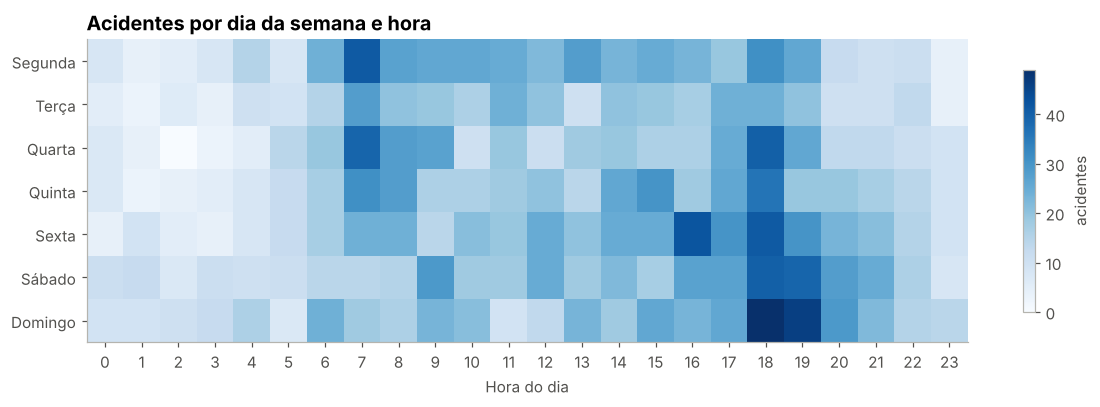

In [7]:
ordem_dias = ['segunda-feira','terça-feira','quarta-feira','quinta-feira','sexta-feira','sábado','domingo']
dia = oc['dia_semana'].str.lower().str.strip()
mapa_calor = pd.crosstab(dia, oc['hora']).reindex([d for d in ordem_dias if d in set(dia)])

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(mapa_calor, aspect='auto', cmap='Blues')
ax.set_yticks(range(len(mapa_calor)), [d.split('-')[0].capitalize() for d in mapa_calor.index])
ax.set_xticks(range(len(mapa_calor.columns)), mapa_calor.columns)
ax.set_xlabel('Hora do dia'); ax.grid(False)
ax.set_title('Acidentes por dia da semana e hora')
plt.colorbar(im, ax=ax, label='acidentes', shrink=0.8)
plt.tight_layout(); plt.show()

### 3. Distribuição, média e mediana

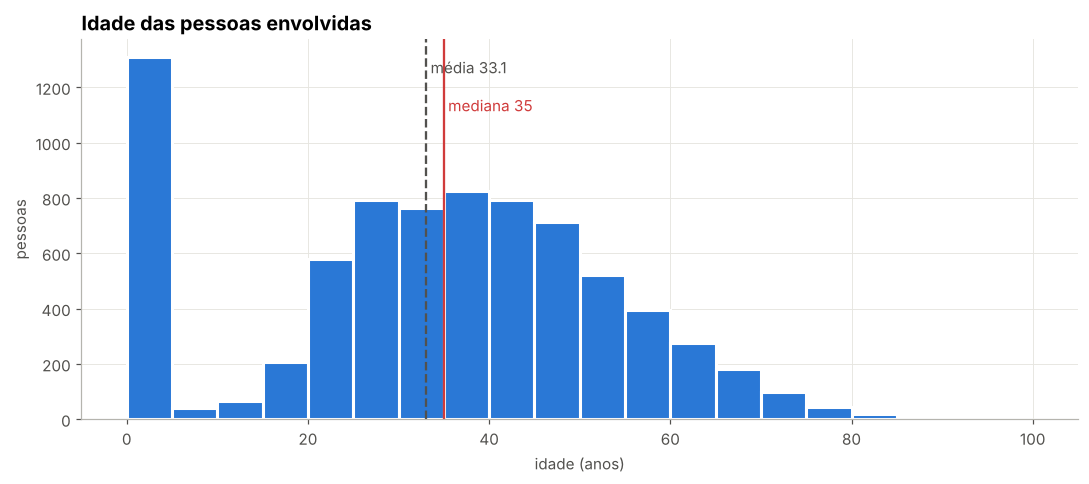

In [8]:
idade = pes['idade'].where(pes['idade'].between(0, 100))   # ignora valores impossíveis só para visualizar
media, mediana = idade.mean(), idade.median()

fig, ax = plt.subplots()
ax.hist(idade.dropna(), bins=range(0, 101, 5), color=AZUL, edgecolor='white', linewidth=2)
ax.axvline(media, color=CINZA, ls='--', lw=1.5); ax.axvline(mediana, color=VERMELHO, ls='-', lw=1.5)
ax.text(media, ax.get_ylim()[1] * 0.95, f' média {media:.1f}', color=CINZA, va='top')
ax.text(mediana, ax.get_ylim()[1] * 0.85, f' mediana {mediana:.0f}', color=VERMELHO, va='top')
ax.set_title('Idade das pessoas envolvidas'); ax.set_xlabel('idade (anos)'); ax.set_ylabel('pessoas')
plt.tight_layout(); plt.show()

In [9]:
num_oc = ['pessoas', 'mortos', 'feridos_leves', 'feridos_graves', 'ilesos', 'veiculos', 'km']
resumo = oc[num_oc].describe().T
resumo['mediana'] = oc[num_oc].median()
resumo['assimetria'] = oc[num_oc].skew()
resumo[['count','mean','mediana','std','min','25%','75%','max','assimetria']].round(2)

,count,mean,mediana,std,min,25%,75%,max,assimetria
pessoas,3013.0,2.51,2.0,2.06,1.0,2.0,3.0,65.0,14.06
mortos,3013.0,0.11,0.0,0.44,0.0,0.0,0.0,16.0,17.15
feridos_leves,3013.0,0.75,1.0,0.92,0.0,0.0,1.0,11.0,2.64
feridos_graves,3013.0,0.36,0.0,0.72,0.0,0.0,1.0,19.0,7.27
ilesos,3013.0,0.98,1.0,1.73,0.0,0.0,1.0,64.0,18.80
veiculos,3013.0,1.94,2.0,0.83,1.0,1.0,2.0,13.0,2.09
km,3013.0,102.30,72.0,94.70,0.0,50.0,125.0,551.0,2.26


> **Leitura:** quando a média é bem maior que a mediana (assimetria > 1), há poucos acidentes com muitos envolvidos puxando a média para cima.

### 4. Outliers (boxplot e regra do IQR)

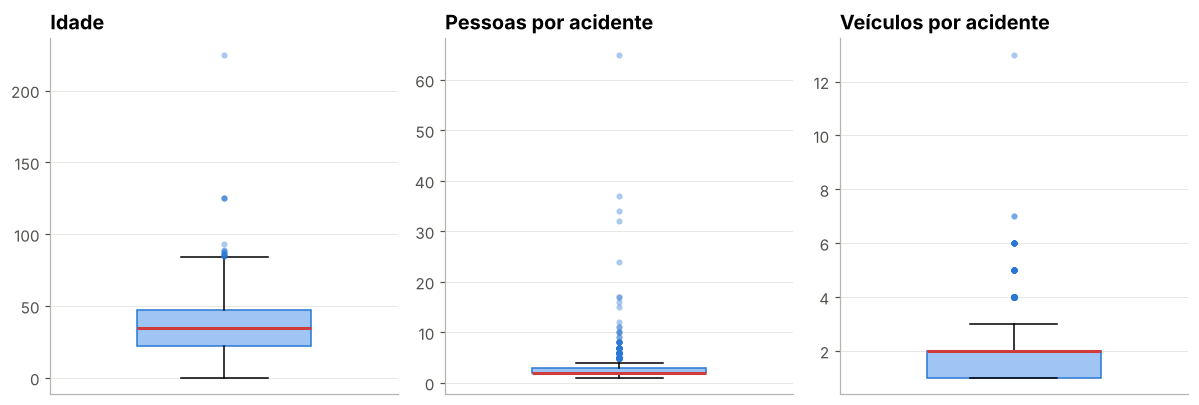

,limite_inf,limite_sup,outliers,% outliers
idade,-15.5,84.5,15.0,0.2
pessoas,0.5,4.5,182.0,6.0
veiculos,-0.5,3.5,126.0,4.2


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, (df, col, tit) in zip(axes, [(pes, 'idade', 'Idade'), (oc, 'pessoas', 'Pessoas por acidente'),
                                     (oc, 'veiculos', 'Veículos por acidente')]):
    ax.boxplot(df[col].dropna(), widths=0.5, patch_artist=True,
               boxprops=dict(facecolor=AZUL_CLARO, edgecolor=AZUL), medianprops=dict(color=VERMELHO, lw=2),
               flierprops=dict(marker='o', markersize=4, markerfacecolor=AZUL, alpha=0.4, markeredgewidth=0))
    ax.set_title(tit); ax.set_xticks([])
plt.tight_layout(); plt.show()

def outliers_iqr(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({'limite_inf': lim_inf, 'limite_sup': lim_sup,
                      'outliers': ((s < lim_inf) | (s > lim_sup)).sum(),
                      '% outliers': round(((s < lim_inf) | (s > lim_sup)).mean() * 100, 1)})

pd.DataFrame({'idade': outliers_iqr(pes['idade'].dropna()),
              'pessoas': outliers_iqr(oc['pessoas']),
              'veiculos': outliers_iqr(oc['veiculos'])}).T

In [11]:
# Quem são os maiores outliers? (acidentes com mais pessoas envolvidas)
oc.nlargest(5, 'pessoas')[['data_inversa','municipio','br','km','tipo_acidente','pessoas','veiculos','mortos','feridos']]

,data_inversa,municipio,br,km,tipo_acidente,pessoas,veiculos,mortos,feridos
2929,2025-12-22,OURICURI,316,65.0,Colisão traseira,65,2,0,1
2588,2025-10-17,SALOA,423,127.0,Saída de leito carroçável,37,1,16,21
2034,2025-08-16,SALGUEIRO,232,507.0,Colisão frontal,34,2,0,8
1173,2025-03-14,SERRA TALHADA,232,415.7,Atropelamento de Animal,32,1,0,12
2164,2025-09-07,ARCOVERDE,232,252.6,Colisão lateral sentido oposto,24,2,0,0


### 5. Correlação entre variáveis numéricas

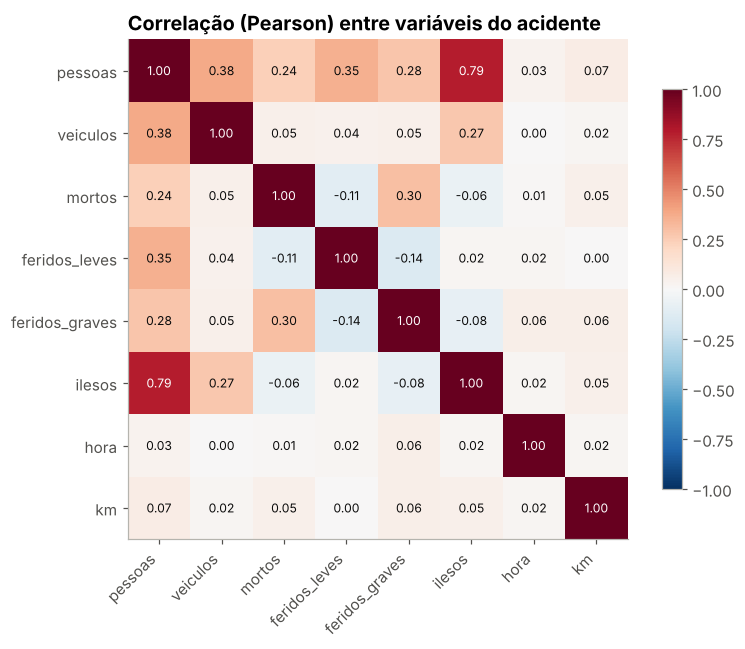

In [12]:
num = oc[['pessoas','veiculos','mortos','feridos_leves','feridos_graves','ilesos','hora','km']]
corr = num.corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)), corr.columns); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if abs(v) > 0.6 else '#0b0b0b')
plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_title('Correlação (Pearson) entre variáveis do acidente')
plt.tight_layout(); plt.show()

> **Leitura:** destaque as correlações fortes (|r| > 0,5) e lembre que correlação não é causalidade.

### 6. Causas, tipos e letalidade

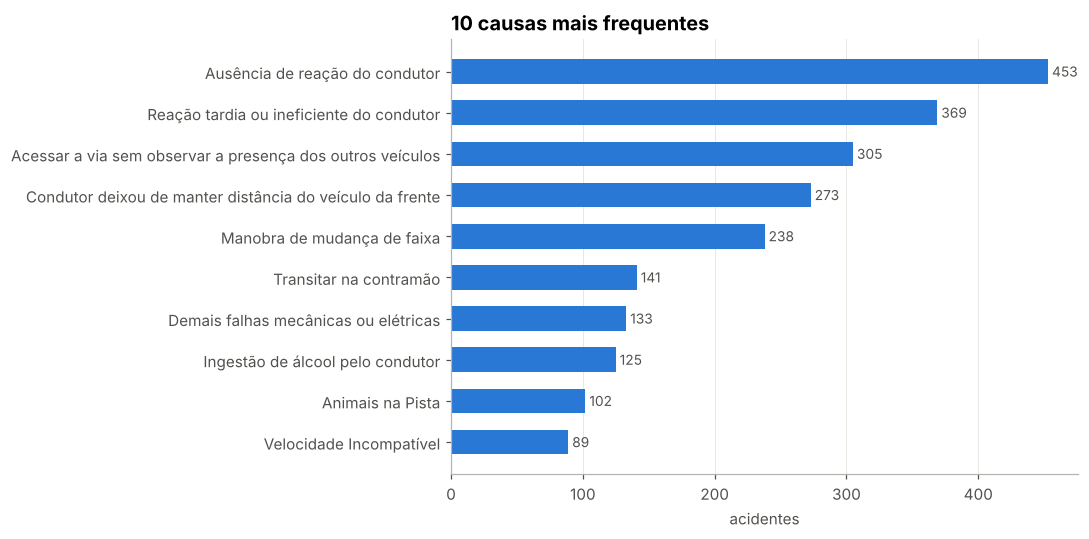

In [13]:
top_causas = oc['causa_acidente'].value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_causas.index, top_causas.values, color=AZUL, height=0.6)
for y, v in enumerate(top_causas.values):
    ax.text(v, y, f' {v}', va='center', color=CINZA, fontsize=9)
ax.set_title('10 causas mais frequentes'); ax.set_xlabel('acidentes'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

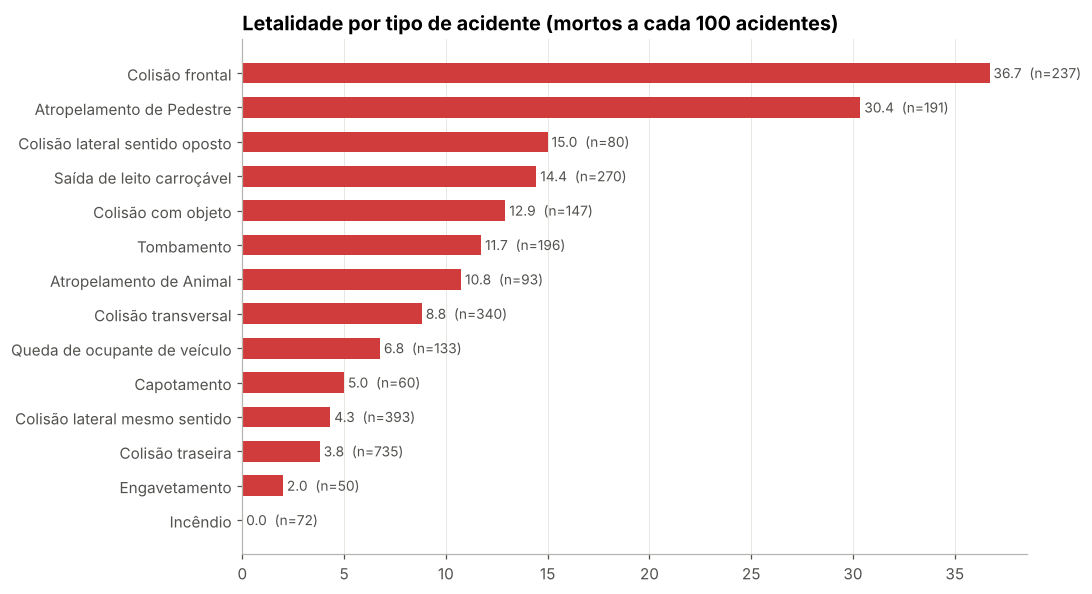

,acidentes,mortos,letalidade
tipo_acidente,,,
Colisão frontal,237,87,36.7
Atropelamento de Pedestre,191,58,30.4
Colisão lateral sentido oposto,80,12,15.0
Saída de leito carroçável,270,39,14.4
Colisão com objeto,147,19,12.9
Tombamento,196,23,11.7
Atropelamento de Animal,93,10,10.8
Colisão transversal,340,30,8.8
Queda de ocupante de veículo,133,9,6.8


In [14]:
# Letalidade = mortos a cada 100 acidentes (só tipos com pelo menos 20 acidentes)
tipo = oc.groupby('tipo_acidente').agg(acidentes=('id','count'), mortos=('mortos','sum'))
tipo = tipo[tipo['acidentes'] >= 20]
tipo['letalidade'] = tipo['mortos'] / tipo['acidentes'] * 100
tipo = tipo.sort_values('letalidade')

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(tipo.index, tipo['letalidade'], color=VERMELHO, height=0.6)
for y, (v, n) in enumerate(zip(tipo['letalidade'], tipo['acidentes'])):
    ax.text(v, y, f' {v:.1f}  (n={n})', va='center', color=CINZA, fontsize=9)
ax.set_title('Letalidade por tipo de acidente (mortos a cada 100 acidentes)'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
tipo.sort_values('letalidade', ascending=False).round(1)

### 7. Dispersão: mapa dos acidentes e cruzamento com a população (IBGE)

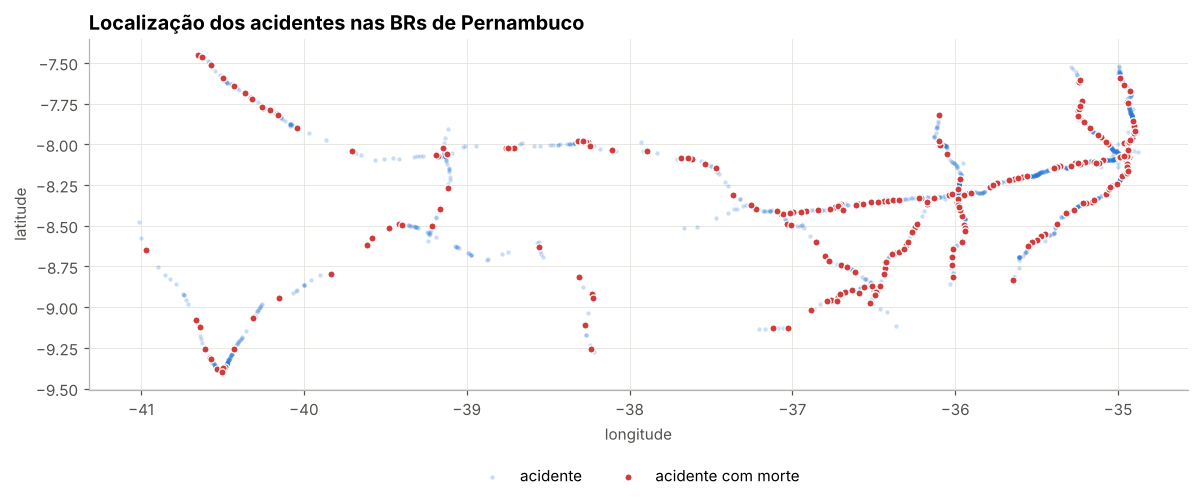

In [15]:
geo = oc[oc['latitude'].between(-10, -7) & oc['longitude'].between(-42, -32)]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.scatter(geo['longitude'], geo['latitude'], s=8, color=AZUL, alpha=0.25, linewidths=0, label='acidente')
g2 = geo[geo['com_morte']]
ax.scatter(g2['longitude'], g2['latitude'], s=22, color=VERMELHO, edgecolor='white', linewidth=0.8,
           label='acidente com morte')
ax.set_title('Localização dos acidentes nas BRs de Pernambuco')
ax.set_xlabel('longitude'); ax.set_ylabel('latitude'); ax.set_aspect('equal'); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout(); plt.show()

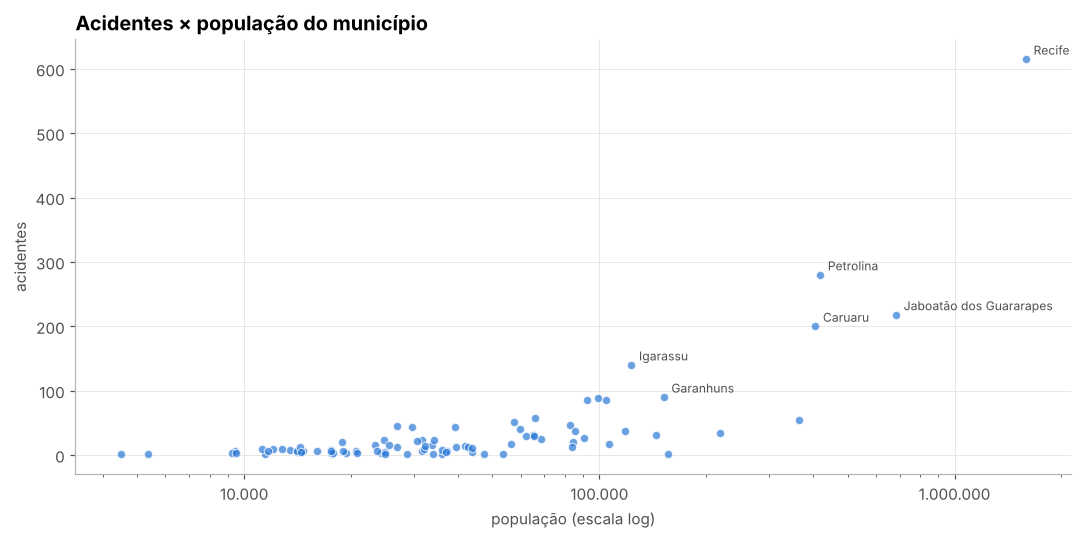

Correlação de Spearman (população × acidentes): 0.67


,municipio,populacao,acidentes,mortos,acid_100mil
61,Pombos,26942,45,7,167.0
38,Itapissuma,29669,43,2,144.9
34,Igarassu,123017,140,4,113.8
70,São Caitano,39243,44,6,112.1
68,Sanharó,18812,20,5,106.3
2,Agrestina,24680,24,6,97.2
31,Gravatá,92429,86,4,93.0
76,Tacaimbó,14330,13,1,90.7
47,Moreno,57654,52,6,90.2
65,Sairé,11213,10,2,89.2


In [16]:
oc['municipio_chave']  = oc['municipio'].map(chave)
pop['municipio_chave'] = pop['municipio'].map(chave)

mun = (oc.groupby('municipio_chave').agg(acidentes=('id','count'), mortos=('mortos','sum'))
         .merge(pop[['municipio_chave','municipio','populacao']], on='municipio_chave', how='inner'))
mun['acid_100mil'] = mun['acidentes'] / mun['populacao'] * 100_000

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(mun['populacao'], mun['acidentes'], s=30, color=AZUL, alpha=0.7, edgecolor='white', linewidth=0.8)
for _, r in mun.nlargest(6, 'acidentes').iterrows():
    ax.annotate(r['municipio'], (r['populacao'], r['acidentes']), xytext=(5, 3), textcoords='offset points',
                fontsize=8, color=CINZA)
ax.set_xscale('log'); ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.')))
ax.set_title('Acidentes × população do município'); ax.set_xlabel('população (escala log)'); ax.set_ylabel('acidentes')
plt.tight_layout(); plt.show()

print('Correlação de Spearman (população × acidentes):', round(mun['populacao'].corr(mun['acidentes'], method='spearman'), 2))
mun.sort_values('acid_100mil', ascending=False).head(10)[['municipio','populacao','acidentes','mortos','acid_100mil']].round(1)

> **Leitura:** municípios pequenos cortados por BRs movimentadas tendem a ter taxa por 100 mil habitantes alta – o risco está na rodovia, não na população local.

### 8. Perfil das vítimas (cruzamento ocorrências × pessoas)

estado_fisico,Ileso,Lesões Graves,Lesões Leves,Óbito
tipo_envolvido,,,,
Cavaleiro,0.0,0.0,66.7,33.3
Condutor,49.1,15.3,30.9,4.7
Passageiro,36.8,16.4,43.5,3.3
Pedestre,1.5,45.8,24.1,28.6


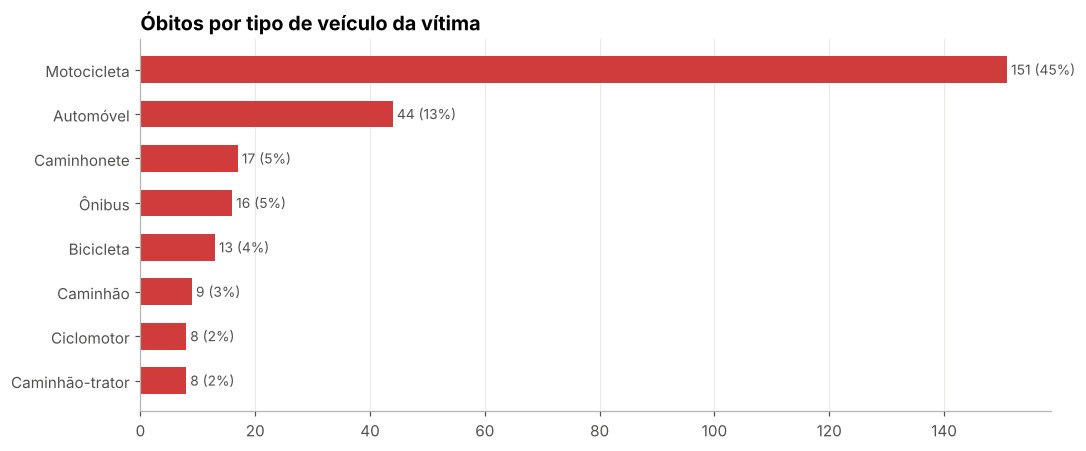

In [17]:
perfil = pes[~pes['estado_fisico'].astype(str).str.match(SEM_INFO)]
tab = pd.crosstab(perfil['tipo_envolvido'], perfil['estado_fisico'], normalize='index').mul(100).round(1)
display(tab)

# Tipo de veículo das vítimas fatais
obitos = pes[pes['estado_fisico'].astype(str).str.contains('bito', case=False)]
veic = obitos['tipo_veiculo'].value_counts().head(8).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(veic.index, veic.values, color=VERMELHO, height=0.6)
for y, v in enumerate(veic.values):
    ax.text(v, y, f' {v} ({v / len(obitos):.0%})', va='center', color=CINZA, fontsize=9)
ax.set_title('Óbitos por tipo de veículo da vítima'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

In [18]:
sexo = pes['sexo'].value_counts(normalize=True).mul(100).round(1)
fx = pd.cut(pes['idade'], [0, 17, 24, 34, 44, 59, 100], labels=['0-17','18-24','25-34','35-44','45-59','60+'])
display(sexo.to_frame('% pessoas'))
pd.crosstab(fx, pes['estado_fisico'], margins=True)

,% pessoas
sexo,
Masculino,71.1
Feminino,19.6
Não Informado,9.3
Ignorado,0.1


estado_fisico,Ileso,Lesões Graves,Lesões Leves,Óbito,All
idade,,,,,
0-17,70,47,89,2,208
18-24,179,168,323,38,708
25-34,608,272,617,59,1556
35-44,795,252,515,59,1621
45-59,841,232,457,99,1629
60+,336,78,171,49,634
All,2829,1049,2172,306,6356


### 9. Onde os acidentes se concentram: BRs e trechos

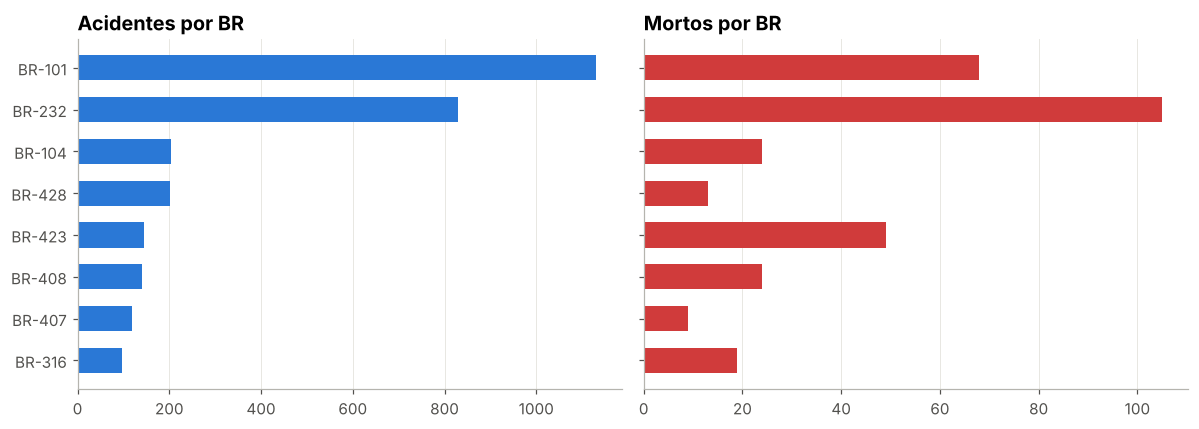

,acidentes,mortos
trecho,,
BR-101 km 60–70,259,9
BR-101 km 70–80,194,11
BR-101 km 40–50,181,7
BR-101 km 50–60,145,9
BR-232 km 0–10,136,5
BR-428 km 180–190,106,2
BR-101 km 80–90,101,5
BR-104 km 60–70,79,1
BR-407 km 120–130,78,3


In [19]:
por_br = (oc.groupby('br').agg(acidentes=('id','count'), mortos=('mortos','sum'))
            .sort_values('acidentes', ascending=False).head(8))
por_br.index = 'BR-' + por_br.index.astype(int).astype(str)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
a1.barh(por_br.index[::-1], por_br['acidentes'][::-1], color=AZUL, height=0.6); a1.set_title('Acidentes por BR')
a2.barh(por_br.index[::-1], por_br['mortos'][::-1], color=VERMELHO, height=0.6); a2.set_title('Mortos por BR')
for a in (a1, a2): a.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

# Trechos críticos: BR + faixa de 10 km
oc['trecho'] = ('BR-' + oc['br'].astype('Int64').astype(str) + ' km '
                + (oc['km'] // 10 * 10).astype('Int64').astype(str) + '–'
                + (oc['km'] // 10 * 10 + 10).astype('Int64').astype(str))
oc.groupby('trecho').agg(acidentes=('id','count'), mortos=('mortos','sum')).nlargest(10, 'acidentes')

### 10. Resumo automático dos principais números (base para o relatório)

In [20]:
pct_morte = oc['com_morte'].mean() * 100
pico_hora = oc['hora'].value_counts().idxmax()
top_dia   = oc['dia_semana'].value_counts().idxmax()
top_causa = oc['causa_acidente'].value_counts().idxmax()
top_letal = tipo['letalidade'].idxmax()
top_br    = por_br.index[0]
moto      = obitos['tipo_veiculo'].astype(str).str.contains('moto', case=False).mean() * 100
masc      = pes['sexo'].astype(str).str.lower().str.startswith('masc').mean() * 100

insights = [
    f'Em 2025 a PRF registrou {len(oc):,} acidentes em PE, com {int(oc.mortos.sum())} mortos e {int(oc.feridos.sum()):,} feridos.',
    f'{pct_morte:.1f}% dos acidentes tiveram pelo menos uma morte.',
    f'O horário com mais acidentes é {pico_hora}h e o dia da semana é {top_dia}.',
    f'A causa mais frequente é "{top_causa}".',
    f'O tipo de acidente mais letal é "{top_letal}" ({tipo.loc[top_letal, "letalidade"]:.1f} mortos a cada 100 acidentes).',
    f'A {top_br} concentra o maior número de acidentes ({por_br.iloc[0, 0]} – {por_br.iloc[0, 0] / len(oc):.0%} do total).',
    f'{moto:.0f}% das vítimas fatais estavam em motocicletas/motonetas.',
    f'{masc:.0f}% das pessoas envolvidas são do sexo masculino; mediana de idade de {mediana:.0f} anos.',
    f'Maior taxa por 100 mil habitantes: {mun.nlargest(1, "acid_100mil").iloc[0]["municipio"]}.',
]
for i, t in enumerate(insights, 1):
    print(f'{i}. {t}')

1. Em 2025 a PRF registrou 3,013 acidentes em PE, com 336 mortos e 3,348 feridos.
2. 10.0% dos acidentes tiveram pelo menos uma morte.
3. O horário com mais acidentes é 18h e o dia da semana é domingo.
4. A causa mais frequente é "Ausência de reação do condutor".
5. O tipo de acidente mais letal é "Colisão frontal" (36.7 mortos a cada 100 acidentes).
6. A BR-101 concentra o maior número de acidentes (1130 – 38% do total).
7. 49% das vítimas fatais estavam em motocicletas/motonetas.
8. 68% das pessoas envolvidas são do sexo masculino; mediana de idade de 35 anos.
9. Maior taxa por 100 mil habitantes: Pombos.


### Próximo passo
Copie a saída da seção 10 e os problemas da seção 1: com eles montamos o **relatório de insights** e o plano de **tratamento (Etapa 3)**.